# Marketing A/B Test — Campaign Effectiveness Analysis

### Business Problem

Companies invest in digital advertising to attract potential customers and increase sales. However, advertising exposure does not necessarily translate into purchases, and marketing campaigns require resources and investment.

The company therefore needs evidence to determine whether displaying advertisements is more effective at generating conversions than showing public service announcements.

### Business Objective

The main business objective is to compare the conversion rates of the Ad and PSA groups and determine whether the observed difference is statistically significant.

## Key Business Question

**Does displaying advertisements lead to a higher conversion rate than displaying public service announcements (PSAs), and is the observed difference statistically significant enough to support a business decision?**

In [1]:
import os

folder_path = r"C:\Users\berta\OneDrive\Desktop\IRONHACK\PROJECT 2"

print("Files in the project folder:")
print(os.listdir(folder_path))


Files in the project folder:
['df_final_demo.txt', 'df_final_experiment_clients.txt', 'df_final_web_data_pt_1.txt', 'df_final_web_data_pt_2.txt', 'marketing_AB.csv', 'tableau_age_completion.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = os.path.join(folder_path, "marketing_AB.csv")
df = pd.read_csv(file_path)

df.head()


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [3]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset dimensions: (588101, 7)

Column names:
['Unnamed: 0', 'user id', 'test group', 'converted', 'total ads', 'most ads day', 'most ads hour']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("Number of duplicate user IDs:", df["user id"].duplicated().sum())

print("\nFirst values of the unnamed column:")
print(df["Unnamed: 0"].head())

print("\nLast values of the unnamed column:")
print(df["Unnamed: 0"].tail())


Missing values per column:
Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

Number of duplicate rows: 0
Number of duplicate user IDs: 0

First values of the unnamed column:
0    0
1    1
2    2
3    3
4    4
Name: Unnamed: 0, dtype: int64

Last values of the unnamed column:
588096    588096
588097    588097
588098    588098
588099    588099
588100    588100
Name: Unnamed: 0, dtype: int64


In [5]:
df = df.drop(columns=["Unnamed: 0"])

print("Updated dataset dimensions:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

df.head()


Updated dataset dimensions: (588101, 6)

Remaining columns:
['user id', 'test group', 'converted', 'total ads', 'most ads day', 'most ads hour']


,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


In [7]:
print("Unique test groups:")
print(df["test group"].value_counts())

print("\nConversion values:")
print(df["converted"].value_counts())

print("\nDays with the most ads:")
print(df["most ads day"].value_counts())

print("\nDescriptive statistics:")
display(df[["total ads", "most ads hour"]].describe())

print("\nMinimum total ads:", df["total ads"].min())
print("Maximum total ads:", df["total ads"].max())
print("Minimum ad hour:", df["most ads hour"].min())
print("Maximum ad hour:", df["most ads hour"].max())


Unique test groups:
test group
ad     564577
psa     23524
Name: count, dtype: int64

Conversion values:
converted
False    573258
True      14843
Name: count, dtype: int64

Days with the most ads:
most ads day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64

Descriptive statistics:


,total ads,most ads hour
count,588101.000000,588101.000000
mean,24.820876,14.469061
std,43.715181,4.834634
min,1.000000,0.000000
25%,4.000000,11.000000
50%,13.000000,14.000000
75%,27.000000,18.000000
max,2065.000000,23.000000



Minimum total ads: 1
Maximum total ads: 2065
Minimum ad hour: 0
Maximum ad hour: 23


In [8]:
total_users = df["user id"].nunique()
total_conversions = df["converted"].sum()
overall_conversion_rate = df["converted"].mean() * 100
average_ads = df["total ads"].mean()

group_sizes = df["test group"].value_counts()

print(f"Total users: {total_users:,}")
print(f"Total conversions: {total_conversions:,}")
print(f"Overall conversion rate: {overall_conversion_rate:.2f}%")
print(f"Average ads per user: {average_ads:.2f}")

print("\nUsers per group:")
print(group_sizes)


Total users: 588,101
Total conversions: 14,843
Overall conversion rate: 2.52%
Average ads per user: 24.82

Users per group:
test group
ad     564577
psa     23524
Name: count, dtype: int64


### User Distribution by Test Group

Before comparing campaign performance, it is important to understand how users are distributed between the Ad and PSA groups. Checking the size of each group helps identify potential imbalances that should be considered when interpreting the results.

**Key question:** How many users were assigned to each test group, and are the Ad and PSA groups balanced in size?

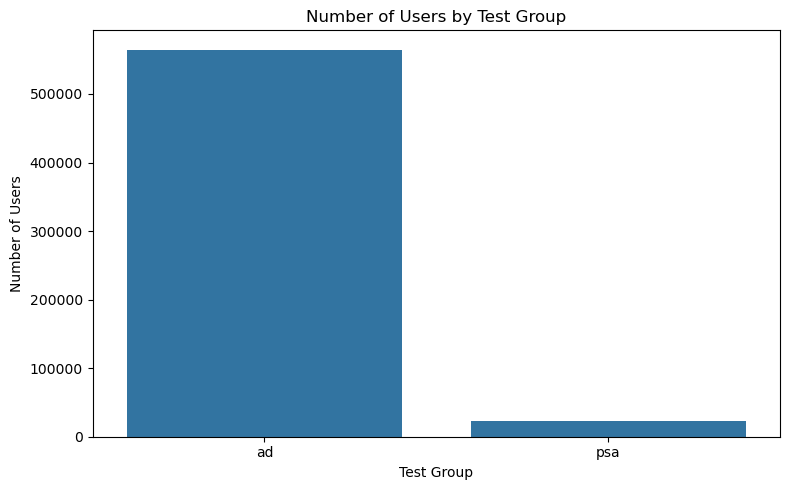

In [9]:
group_counts = df["test group"].value_counts().reindex(["ad", "psa"])

plt.figure(figsize=(8, 5))
sns.barplot(x=group_counts.index, y=group_counts.values)

plt.title("Number of Users by Test Group")
plt.xlabel("Test Group")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()


### Conversion Rate by Test Group

The number of users in each group does not tell us which campaign performs better. To evaluate effectiveness, we need to compare the proportion of users who completed a purchase in each group.

The conversion rate is calculated by dividing the number of users who converted by the total number of users in the group and multiplying by 100.

**Key question:** Does the Ad group have a higher conversion rate than the PSA control group?

Conversion rate by test group:
test group
ad     2.55
psa    1.79
Name: converted, dtype: float64


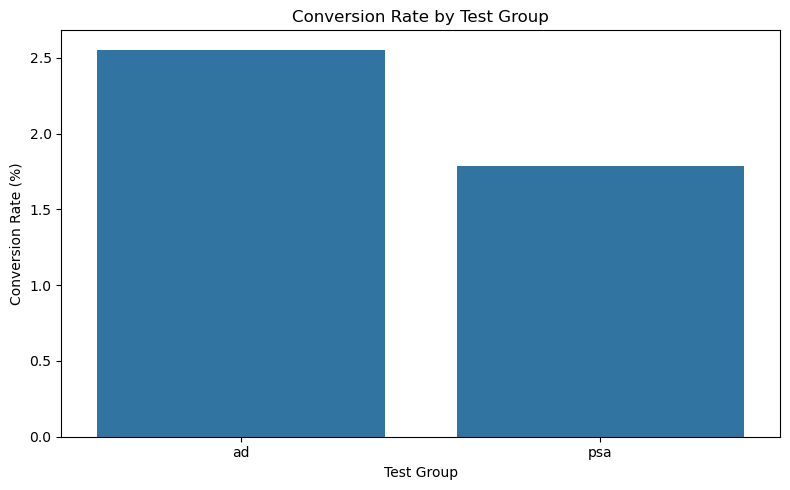

In [10]:
conversion_rates = df.groupby("test group")["converted"].mean() * 100

print("Conversion rate by test group:")
print(conversion_rates.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=conversion_rates.index,
    y=conversion_rates.values
)

plt.title("Conversion Rate by Test Group")
plt.xlabel("Test Group")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()


**Preliminary observation**

The Ad group achieved a conversion rate of 2.50%, compared with 1.80% in the PSA control group. This suggests that users exposed to advertisements were more likely to convert than users shown public service announcements.

However, this is a descriptive comparison only. A statistical hypothesis test is required to determine whether the observed difference is statistically significant.

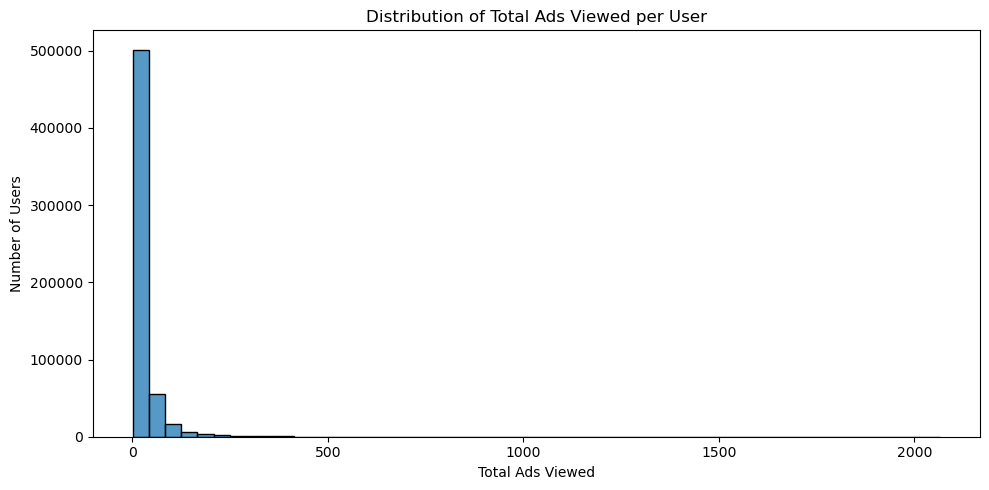

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="total ads",
    bins=50
)

plt.title("Distribution of Total Ads Viewed per User")
plt.xlabel("Total Ads Viewed")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()


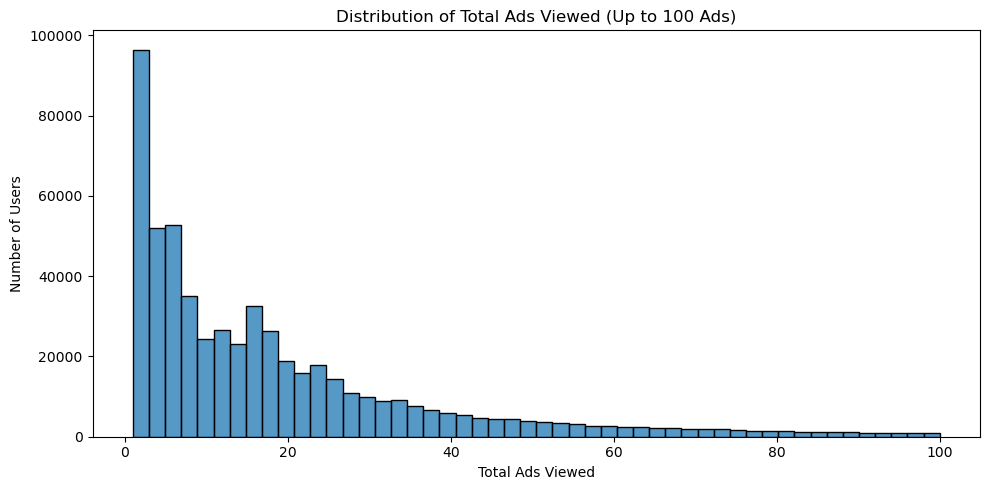

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["total ads"] <= 100],
    x="total ads",
    bins=50
)

plt.title("Distribution of Total Ads Viewed (Up to 100 Ads)")
plt.xlabel("Total Ads Viewed")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()


**Key Findings**

Most users saw a relatively small number of ads. As the number of ads increases, the number of users decreases. A few users saw many more ads than the rest, but we will keep these values because they may reflect real user behavior.

## Campaign Performance Analysis

In this section, we will compare the Ad and PSA groups to understand how well the advertising campaign performed.

**Key question:** Did the Ad group achieve a higher conversion rate than the PSA group?

In [14]:
campaign_performance = df.groupby("test group").agg(
    users=("user id", "nunique"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)

campaign_performance["conversion_rate"] *= 100

campaign_performance.round(2)


,users,conversions,conversion_rate
test group,,,
ad,564577,14423,2.55
psa,23524,420,1.79


In [15]:

ad_rate = campaign_performance.loc["ad", "conversion_rate"]
psa_rate = campaign_performance.loc["psa", "conversion_rate"]

absolute_difference = ad_rate - psa_rate

relative_improvement = (absolute_difference / psa_rate) * 100

print(f"Ad conversion rate: {ad_rate:.2f}%")
print(f"PSA conversion rate: {psa_rate:.2f}%")
print(f"Absolute difference: {absolute_difference:.2f} percentage points")
print(f"Relative improvement: {relative_improvement:.2f}%")


Ad conversion rate: 2.55%
PSA conversion rate: 1.79%
Absolute difference: 0.77 percentage points
Relative improvement: 43.09%


### Key Findings

The Ad group achieved a conversion rate of 2.55%, compared with 1.79% for the PSA group. This represents a difference of 0.77 percentage points and a relative improvement of 43.09%.

These results suggest that advertising may improve conversions. However, we still need a statistical test to determine whether the difference is significant.

## Hypothesis Testing

We will use a two-proportion z-test to determine whether the difference in conversion rates between the Ad and PSA groups is statistically significant.

**Hypotheses**

- **Null hypothesis (H₀):** The conversion rates of the Ad and PSA groups are equal.
- **Alternative hypothesis (H₁):** The conversion rates of the Ad and PSA groups are different.

The significance level is set at 5% (α = 0.05).

In [16]:
from statsmodels.stats.proportion import proportions_ztest

conversions = campaign_performance.loc[["ad", "psa"], "conversions"].to_numpy()

users = campaign_performance.loc[["ad", "psa"], "users"].to_numpy()

z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=users,
    alternative="two-sided"
)

alpha = 0.05

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Significance level: {alpha}")


Z-statistic: 7.3701
P-value: 1.70528e-13
Significance level: 0.05


### Hypothesis Test Results

The two-proportion z-test returned a z-statistic of 7.3701 and a p-value of 1.71 × 10⁻¹³.

Since the p-value is below the 0.05 significance level, we reject the null hypothesis. There is strong statistical evidence that the conversion rates differ between the Ad and PSA groups.

Because the Ad group has the higher observed conversion rate, the results favor the advertising campaign. However, statistical significance alone does not establish profitability or prove that the campaign is commercially worthwhile.

In [17]:
if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print("The conversion rates are statistically significantly different.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in conversion rates.")


Decision: Reject the null hypothesis.
The conversion rates are statistically significantly different.


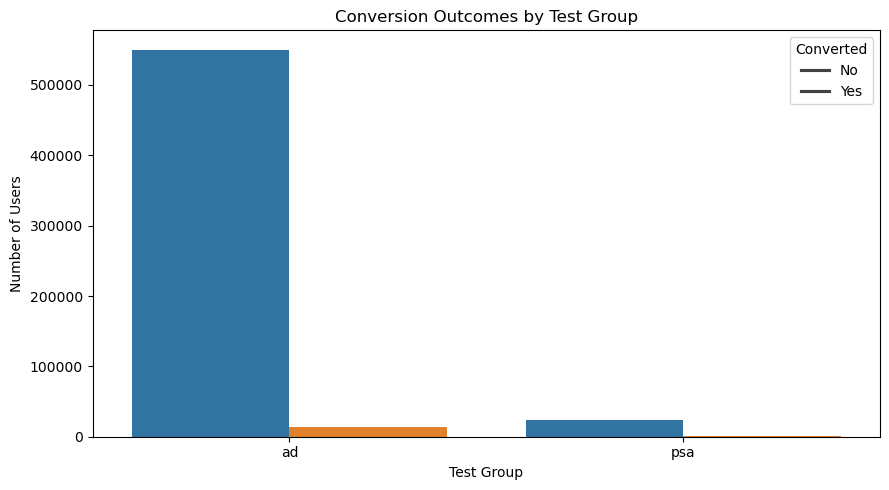

In [18]:
conversion_counts = df.groupby(
    ["test group", "converted"]
).size().reset_index(name="users")

plt.figure(figsize=(9, 5))
sns.barplot(
    data=conversion_counts,
    x="test group",
    y="users",
    hue="converted"
)

plt.title("Conversion Outcomes by Test Group")
plt.xlabel("Test Group")
plt.ylabel("Number of Users")
plt.legend(title="Converted", labels=["No", "Yes"])
plt.tight_layout()
plt.show()


In [19]:
tableau_file = os.path.join(
    folder_path,
    "marketing_AB_clean.csv"
)

df.to_csv(tableau_file, index=False)

print("Clean dataset exported successfully:")
print(tableau_file)


Clean dataset exported successfully:
C:\Users\berta\OneDrive\Desktop\IRONHACK\PROJECT 2\marketing_AB_clean.csv
